# Lab: Neural Models - Learning, Depth, Activations, and Output Layers

**Student:** Mehta Prem (2024ADPS0851G)  
**Scenario:** Two redundant binary sensors; warn exactly when they disagree (XOR).

## Task 1: Understand the problem before coding

### 1.1 Problem specification
Write the input space $\mathcal{X}$, output space $\mathcal{Y}$, and all four labelled examples.

**Answer:**  
- Input space: $\mathcal{X} = \{0,1\}^2 = \{(0,0),(0,1),(1,0),(1,1)\}$  
- Output space: $\mathcal{Y} = \{0,1\}$ (1 = disagreement warning)  
- Labelled examples: $(0,0)\to 0$, $(0,1)\to 1$, $(1,0)\to 1$, $(1,1)\to 0$

### 1.2 Sketch of the four points


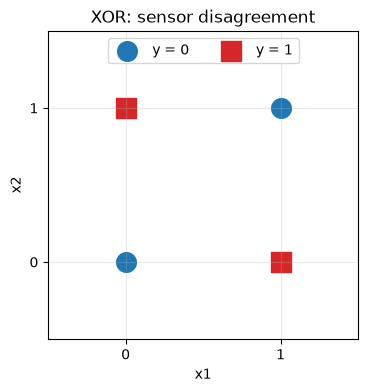

In [1]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([0, 1, 1, 0], dtype=float)

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", s=200, label="y = 0")
ax.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red", s=200, marker="s", label="y = 1")
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.grid(True, alpha=0.3)
ax.legend(loc="upper center", ncol=2)
ax.set_title("XOR: sensor disagreement")
plt.show()

### 1.3 Why can one straight line not separate the classes?

**Answer:**  
The two classes sit on opposite diagonals of the unit square: the class-1 points $(0,1),(1,0)$ lie on one diagonal and the class-0 points $(0,0),(1,1)$ on the other. A line $w_1x_1+w_2x_2+b=0$ would have to keep each diagonal's two points on the same side, but the segments joining each pair cross at $(0.5,0.5)$, so no such line exists.

**Algebraic proof.** A separating line needs  
$b<0$ (for $(0,0)$), $w_1+w_2+b<0$ (for $(1,1)$), $w_1+b>0$ (for $(1,0)$), $w_2+b>0$ (for $(0,1)$).  
Adding the last two gives $w_1+w_2+2b>0$. Adding the first two gives $w_1+w_2+2b<0$. Contradiction, so no $(w_1,w_2,b)$ works.

### 1.4 Prediction: single affine layer + sigmoid
What will happen if we train only $\sigma(w_1 x_1 + w_2 x_2 + b)$ on these four points?

**Prediction:**  
A single affine layer plus sigmoid is a linear classifier, so it can get at most 3 of the 4 points right. Binary cross-entropy is convex in $(w,b)$, and its minimum is at $w_1=w_2=b=0$: the gradient there is $\sum_i (p_i-y_i)x_i = 0$ by symmetry. So I predict the model outputs $p\approx 0.5$ for every input, the loss plateaus near $\ln 2\approx 0.693$, and accuracy is only about 2/4 (which points count as correct depends on how $p=0.5$ is thresholded).

### Task 1 Think About It
A model can have many parameters and still have the wrong kind of representation. What scientific claim about representation does XOR let us test with only four data points?

**Answer:**  
XOR lets us test that the kind of representation matters more than the number of parameters. A hidden layer with a nonlinear activation can learn a new representation of the inputs in which the classes are linearly separable, and the output layer then separates them with one line. With four points we can check this directly: the linear model fails and the 2-2-1 nonlinear model succeeds.

## Task 2: Design the intelligent agent

**Model specification**
- Architecture: 2 inputs $\to$ 2 hidden units $\to$ 1 output
- Hidden activation: sigmoid 
- Output: sigmoid, giving $p=P(y=1\mid x)$
- Loss: binary cross-entropy, $L=-\frac14\sum_i\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right]$
- Optimiser: gradient-based (full-batch)

### 2.1 Why is the hidden nonlinearity scientifically necessary?
Without it the network is $W_2(W_1x+b_1)+b_2 = (W_2W_1)x + (W_2b_1+b_2) = W_{\text{eff}}\,x + b_{\text{eff}}$, which is a single affine layer in disguise. Adding affine-only depth therefore adds no representational power, and XOR (not linearly separable) stays impossible. The ingredient that helps is the nonlinearity, not the depth.

### 2.2 Why is sigmoid + binary cross-entropy a sensible pairing?
- The target is a single yes/no answer, so we need one number in $(0,1)$. The sigmoid gives $p=P(y=1)$, and $P(y=0)=1-p$ follows automatically.
- BCE is the negative log-likelihood of a Bernoulli model with parameter $p$, so minimising it is maximum-likelihood estimation for this output.
- The pairing has a clean gradient: $\partial L/\partial z = p-y$ for the logit $z$. The sigmoid's derivative cancels, so a confidently wrong output does not get a vanishing gradient.

### 2.3 Evidence of successful learning
1. **Final loss** is close to 0 (for example below 0.05), well below the $\ln 2\approx0.693$ plateau of the linear model.
2. **All four thresholded predictions** match the labels, with probabilities clearly away from 0.5.
3. **Gradient check:** the first-layer gradient is nonzero during training, and the loss decreases steadily (no NaN, no oscillation).
4. **Repeated runs:** across several random seeds, report how often training succeeds. A 2-2-1 network can get stuck, so one lucky run is not enough evidence.

### Task 2 Think About It
The hidden units are not given target values. If the network learns XOR, what has determined what each hidden unit should compute? Relate your answer to the role of backpropagation.

**Answer:**  
Each hidden unit computes $h_j=\sigma(w_j^\top x+b_j)$, and what it ends up computing is decided by the output-layer error. Backpropagation applies the chain rule to the loss, so each hidden weight receives a gradient $\partial L/\partial w_j$ that measures how changing that weight would change the final loss, passed back through the output weights. The optimiser then moves the weights downhill on that gradient. Over training, each hidden unit is pushed towards whatever feature makes the output's job easier.

## Task 3: Use an LLM to generate a first implementation

### 3.1 Exact prompt used
> I want to build a small autonomous device with two redundant binary sensors, x1 and x2. The device should raise a sensor-disagreement warning exactly when one sensor is active and the other is inactive. The required decision rule is therefore XOR:
> (0,0) -> 0
> (0,1) -> 1
> (1,0) -> 1
> (1,1) -> 0
>
> We will create a 2 input -> 2 hidden -> 1 output neural model with tanh activation function. It should have logits with BCEWithLogitsLoss in PyTorch with random weights initialisation. Use full batch training for 4 thousand steps. For the Optimizer, choose Adam with lr = 1e-3.
>
> Generate minimal PyTorch code for the following model and dataset. Do not change the architecture or task. After training, report the final loss, all four probabilities, thresholded labels, first-layer weight-gradient tensor. Set a random seed for reproducibility and explain each test in one sentence. Report the initial and Final loss. 

### 3.2 Generated code

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# Set random seed for reproducibility
torch.manual_seed(42)

# XOR Dataset
X = torch.tensor([[0.0, 0.0],
                  [0.0, 1.0],
                  [1.0, 0.0],
                  [1.0, 1.0]])
y = torch.tensor([[0.0],
                  [1.0],
                  [1.0],
                  [0.0]])

# Define model architecture (2 inputs -> 2 hidden -> 1 output)
model = nn.Sequential(
    nn.Linear(2, 2),
    nn.Tanh(),
    nn.Linear(2, 1)
)

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# Calculate initial loss before training
initial_logits = model(X)
initial_loss = criterion(initial_logits, y).item()

# Full batch training for 4,000 steps
for step in range(4000):
    optimizer.zero_grad() 
    logits = model(X) #forward pass
    loss = criterion(logits, y) #scalar loss
    loss.backward() #auto-diff
    optimizer.step() #optimiser changes parameters

# Retrieve final metrics
final_loss = loss.item()
final_logits = model(X)
probs = torch.sigmoid(final_logits)
thresholded_labels = (probs > 0.5).int()
first_layer_grad = model[0].weight.grad

# Output formatting
print(f"Initial Loss: {initial_loss:.4f}")
print(f"Final Loss: {final_loss:.4f}")
print(f"Probabilities:\n{probs.detach().numpy()}")
print(f"Thresholded Labels:\n{thresholded_labels.detach().numpy()}")
print(f"First-Layer Weight Gradient Tensor:\n{first_layer_grad.numpy()}")

Initial Loss: 0.7563
Final Loss: 0.0447
Probabilities:
[[0.03016567]
 [0.93219453]
 [0.94509006]
 [0.02112125]]
Thresholded Labels:
[[0]
 [1]
 [1]
 [0]]
First-Layer Weight Gradient Tensor:
[[ 0.00626174 -0.00218701]
 [ 0.00275942 -0.0046804 ]]


### 3.3 Code inspection (by hand, before trusting the output)
- **Forward pass:** `logits = model(X)`, a raw `Linear` output, with no sigmoid in the model.
- **Scalar loss:** `loss = criterion(logits, y)`, BCE with the sigmoid applied inside.
- **Reverse-mode autodiff:** `loss.backward()` fills `.grad` on every parameter.
- **Optimiser step:** `optimizer.step()` (Adam) changes the parameters using those gradients.
- **Subtle issue:** `first_layer_grad` and `final_loss` come from the last `backward()`, which ran *before* the final `optimizer.step()`. They belong to the parameters one step earlier than those used for the printed probabilities. Here the difference is negligible, but a cleaner version re-computes loss and gradient once after training.

### 3.4 Results (seed 42, CPU)
Initial loss 0.7563, final loss 0.0447, probabilities about [0.030, 0.932, 0.945, 0.021], labels [0, 1, 1, 0], first-layer gradient about [[0.0063, -0.0022], [0.0028, -0.0047]]. The loss was still about 0.687 (the linear plateau) at step 500 and only fell clearly afterwards.

### Task 3 Think About It
Which parts of the lab can be verified by reading the code, and which only by running it?

**Answer:**  
- **Verifiable by reading the code alone:** syntax, design (architecture, loss and output pairing, optimiser choice) and the order of steps (zero gradients, forward, loss, backward, step).
- **Verifiable only by running it:** convergence, the actual loss values, the gradients, and whether learning succeeded or failed.

In [3]:
def run(seed, steps=4000, lr=1e-3):
    torch.manual_seed(seed)
    m = nn.Sequential(nn.Linear(2, 2), nn.Tanh(), nn.Linear(2, 1))
    c = nn.BCEWithLogitsLoss()
    o = optim.Adam(m.parameters(), lr=lr)
    for _ in range(steps):
        o.zero_grad()
        l = c(m(X), y)
        l.backward()
        o.step()
    with torch.no_grad():
        p = torch.sigmoid(m(X)).squeeze()
        l = c(m(X), y).item()
    return l, p, int(((p > 0.5).float() == y.squeeze()).all())

for lr in (1e-3, 1e-2):
    print("lr", lr)
    ok = 0
    for s in range(10):
        l, p, a = run(s, lr=lr)
        ok += a
        print(s, round(l, 4), p.numpy().round(3), "OK" if a else "FAIL")
    print("success", ok, "/10")

lr 0.001
0 0.0372 [0.03  0.959 0.949 0.023] OK
1 0.3592 [0.013 0.496 0.985 0.507] FAIL
2 0.4843 [0.337 0.991 0.33  0.336] FAIL
3 0.052 [0.049 0.932 0.949 0.035] OK
4 0.0564 [0.042 0.923 0.938 0.039] OK
5 0.3586 [0.014 0.986 0.495 0.505] FAIL
6 0.3562 [0.009 0.99  0.496 0.505] FAIL
7 0.4833 [0.008 0.665 0.663 0.67 ] FAIL
8 0.3576 [0.011 0.993 0.491 0.504] FAIL
9 0.3588 [0.01  0.99  0.493 0.507] FAIL
success 3 /10
lr 0.01
0 0.0005 [0.    0.999 0.999 0.   ] OK
1 0.3467 [0.  0.5 1.  0.5] FAIL
2 0.0003 [0.    1.    0.999 0.   ] OK
3 0.0006 [0.    0.999 0.999 0.   ] OK
4 0.0007 [0.    0.999 0.999 0.   ] OK
5 0.3467 [0.  1.  0.5 0.5] FAIL
6 0.3467 [0.  1.  0.5 0.5] FAIL
7 0.4774 [0.    0.667 0.667 0.667] FAIL
8 0.3467 [0.  1.  0.5 0.5] FAIL
9 0.3467 [0.  1.  0.5 0.5] FAIL
success 4 /10


## Task 4: Test the model

### 4A. Seed robustness
**Prediction:** all 10 seeds (0 to 9) will reach all four labels correct, because the model learns from whatever random initialisation it is given.

**Result:** the prediction was wrong. With Adam at lr=1e-3 and 4000 steps, only 3/10 seeds succeeded (0, 3, 4). With lr=1e-2, only 4/10 succeeded (0, 2, 3, 4).

**Interpretation:** a 2-2-1 network has almost no spare capacity, so some initialisations end up in a poor configuration that gradient descent cannot escape. The failures are not just slow runs: at lr=1e-2 five seeds stop at a loss of exactly 0.3467 (two inputs stuck at p=0.5, the other two correct) and one at 0.4774 (three inputs at p=0.667). A single successful seed is therefore not evidence that the method works.